### Lifetime Maximum Intensity distribution

In [1]:
%cd 
%cd CHAZ/CHAZv2/

/home/miriamn
/home/miriamn/CHAZ/CHAZv2


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.collections import LineCollection
from matplotlib.colors import Normalize
import sys
import os, glob
import xarray as xr

from scipy.stats import gaussian_kde

## most correct would probably be to seperate this... 
### get variables from chaz run
import Namelist as gv

### TEMPORARY (hopefully) code snippet so that the HTML view of datasets/dataarrays is viewable in darkmode on jupyter lab/VS code
from IPython.display import HTML, display

display(HTML("""
<style>
    .xr-wrap {
        --xr-background-color-row-odd: rgba(100, 100, 100, 0.10) !important;
        --xr-background-color-row-even: rgba(30, 30, 30, 0.10) !important;
    }
</style>
"""))


### N.B OVERWRITE CHECK IS INTENTIONALLY BROKEN 

In [3]:


# base_dir      = "/xpt/taroko.local/data0/clee/ERA5/wdir/netcdf/"
# file_pattern  = "global_2019_2ens00[0-9]_pre.nc"

# filenames = glob.glob(os.path.join(base_dir, file_pattern))

In [4]:
# ds = xr.open_dataset(gv.output_path+"ERA5_2012_ens000.nc")

In [ ]:
version_configs = {
    'ERA5-Original-CHAZ': {
        'base_dir': "/xpt/taroko.local/data0/clee/ERA5/wdir/netcdf/",
        "year_range": (1950, 2020),   
        "output_dir": gv.output_path,  
        #"file_pattern": "global_2019_2ens*_pre.nc",
        "file_pattern": "global_2019_2ens00[0-3]_pre.nc",
        "name": 'ERA5-Original-CHAZ',
        
    },
    'ERA5-Updated-CHAZ': {
        'base_dir': gv.output_path,
        "year_range": (gv.Year1, gv.Year2),
        "file_pattern": "ERA5_*_ens*.nc",
        "output_dir": gv.output_path, 
        "name": 'ERA5-Updated-CHAZ',
    }
}

def _get_basin_mask(latitude, longitude, basin):
    """
    Determine which storms have at least one track point inside a selected ocean basin.

    latitude, longitude:
        xarray.DataArray with dimensions (lifelength, stormID)

    Returns:
        1-D boolean numpy array with length stormID
    """

    if basin == 'ATL':
        # ~100°W–20°E, 0–60°N
        point_mask = (
            (latitude >= 0) &
            (latitude <= 60) &
            (
                (longitude >= 260) |
                (longitude <= 20)
            )
        )

    elif basin == 'WNP':
        # ~100°E–180°E, 0–50°N
        point_mask = (
            (latitude >= 0) &
            (latitude <= 50) &
            (longitude >= 100) &
            (longitude <= 180)
        )

    elif basin == 'GLOBAL':
        # 0–360°, -60–60°
        point_mask = (
            (latitude >= -60) &
            (latitude <= 60)
        )

    else:
        raise ValueError(
            f"Unknown basin: {basin}. "
            "Choose from 'ATL', 'WNP', or 'GLOBAL'."
        )

    ## A storm counts as 'in the ocean basin' if ANY part of its track is within the basin.
    storm_mask = point_mask.any(dim='lifelength')

    return storm_mask.values


def _enumerate_files(cfg):
    base_dir      = cfg["base_dir"]
    file_pattern  = cfg["file_pattern"]
    name          = cfg["name"]
    year_range    = cfg["year_range"]

    filenames = glob.glob(os.path.join(base_dir, file_pattern))
    years_span = year_range[1] - year_range[0] + 1

    if name == 'ERA5-Updated-CHAZ':
        years = {str(y) for y in range(year_range[0], year_range[1] + 1)}
        fnames = sorted([
            f for f in filenames
            if f.split('_')[1] in years])

        nyears_eff = len(fnames)

    elif name == 'ERA5-Original-CHAZ':
        fnames = sorted(filenames)
        nyears_eff = years_span * max(1, len(fnames))

    else:
        raise ValueError(f"Unknown configuration: {name}")

    #return fnames   
    return fnames, nyears_eff


def get_vmax(filenames, basin_key, output_path):
    """Read all files and return maximum wind speed for each storm/event."""

    vmax_all = []

    for filename in filenames:
        #print(f"Reading: {filename}")

        with xr.open_dataset(filename) as ds:
            # lat/lon are data variables associated with stormID
            lat = ds.latitude
            lon = ds.longitude

            basin_mask = _get_basin_mask(
                lat,
                lon,
                basin_key
            )

            # Mwspd dimensions: (ensembleNum, lifelength, stormID)
            #
            # Find maximum over storm lifetime.
            # vmax dimensions: (ensembleNum, stormID)
            vmax = ds.Mwspd.max(dim='lifelength', skipna=True)

            # Keep only storms in selected basin
            vmax = vmax[:, basin_mask]

            # Remove NaNs
            vmax = vmax.values
            vmax = vmax[~np.isnan(vmax)]

            vmax_all.append(vmax)

    if not vmax_all:
        raise ValueError("No valid data found.")

    vmax_concat = np.concatenate(vmax_all)

    print(f'saving vmax array to {output_path}')
    np.save(output_path, vmax_concat)

    return vmax_concat


def plot_LMI(basin_key):
    fig, ax = plt.subplots(figsize=(7, 5))

    colors = {
        'ERA5-Original-CHAZ': 'royalblue',
        'ERA5-Updated-CHAZ': 'darkorange',
    }

    for name, cfg in version_configs.items():
    
        filenames, nyears_eff = _enumerate_files(cfg)

        print(
            f"{name}: "
            f"{len(filenames)} files, "
            f"{nyears_eff} effective years"
        )   
        ## check if vmax has already been calculated:

        ## TODO: add mkdir if doesn't exist like in track-density/frequency
        #out_root = cfg["output_dir"]
        out_root = gv.output_path
        out_dir = os.path.join(out_root, "VMAX")
        output_path = os.path.join(out_dir, f"vmax_{name}_{basin_key}_{nyears_eff}.npy")

        if os.path.exists(output_path):
            ## IMPORT
            vmax = np.load(output_path)
            print(output_path)
        else:
            vmax = get_vmax(filenames, basin_key, output_path)

        # bins = np.arange(25, 200, 5)
        
        # ### CHANGE THIS TO PDF
        # plt.hist(vmax, bins = bins, density = True, 
        #          alpha = 0.5, label = name, color = colors[name])

        # Remove NaNs/infinite values
        vmax = vmax[np.isfinite(vmax)]

        # Kernel density estimate
        kde = gaussian_kde(vmax)

        # Wind-speed range
        # x_grid = np.linspace(
        #     max(0, vmax.min()),
        #     vmax.max(),
        #     500
        # )

        x_grid = np.linspace(25, 200, 500)

        pdf = kde(x_grid)

        ax.plot(
            x_grid,
            pdf,
            color=colors[name],
            linewidth=2,
            label=name
        )

    ax.set_xlabel('Max Wind Speed (m/s)')
    ax.set_ylabel('Probability Density')

    ax.legend()
    ax.grid(alpha=0.25)

    plt.tight_layout()

    plt.title(f'Lifetime Maximum Intensity - {basin_key}')
    plt.legend()
    plt.show()

    return vmax

        

ERA5-Original-CHAZ: 4 files, 284 effective years
saving vmax array to /data0/miriamn/CHAZvectorized/output/101826-landmask-check/VMAX/vmax_ERA5-Original-CHAZ_GLOBAL_284.npy
ERA5-Updated-CHAZ: 150 files, 150 effective years
saving vmax array to /data0/miriamn/CHAZvectorized/output/101826-landmask-check/VMAX/vmax_ERA5-Updated-CHAZ_GLOBAL_150.npy


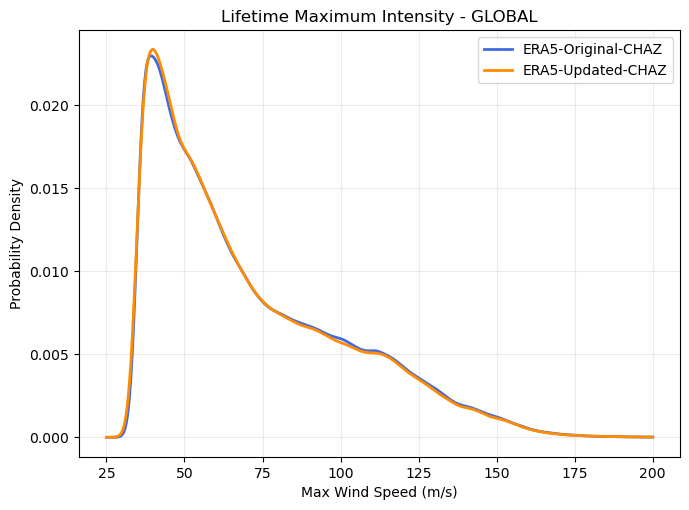

ERA5-Original-CHAZ: 4 files, 284 effective years
saving vmax array to /data0/miriamn/CHAZvectorized/output/101826-landmask-check/VMAX/vmax_ERA5-Original-CHAZ_ATL_284.npy
ERA5-Updated-CHAZ: 150 files, 150 effective years
saving vmax array to /data0/miriamn/CHAZvectorized/output/101826-landmask-check/VMAX/vmax_ERA5-Updated-CHAZ_ATL_150.npy


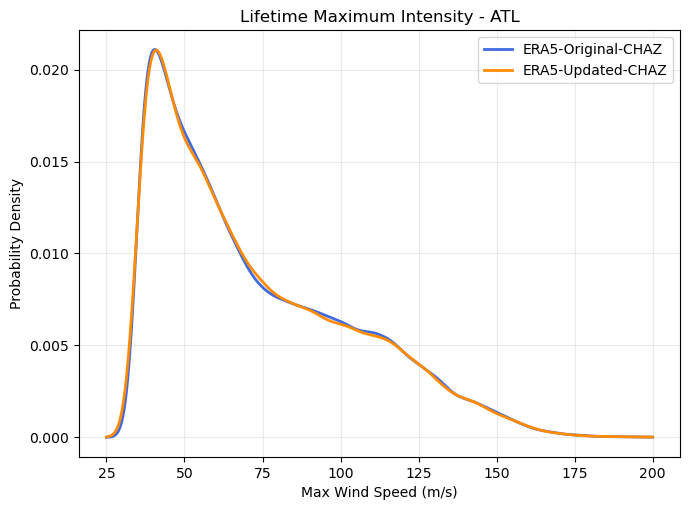

ERA5-Original-CHAZ: 4 files, 284 effective years
saving vmax array to /data0/miriamn/CHAZvectorized/output/101826-landmask-check/VMAX/vmax_ERA5-Original-CHAZ_WNP_284.npy
ERA5-Updated-CHAZ: 150 files, 150 effective years
saving vmax array to /data0/miriamn/CHAZvectorized/output/101826-landmask-check/VMAX/vmax_ERA5-Updated-CHAZ_WNP_150.npy


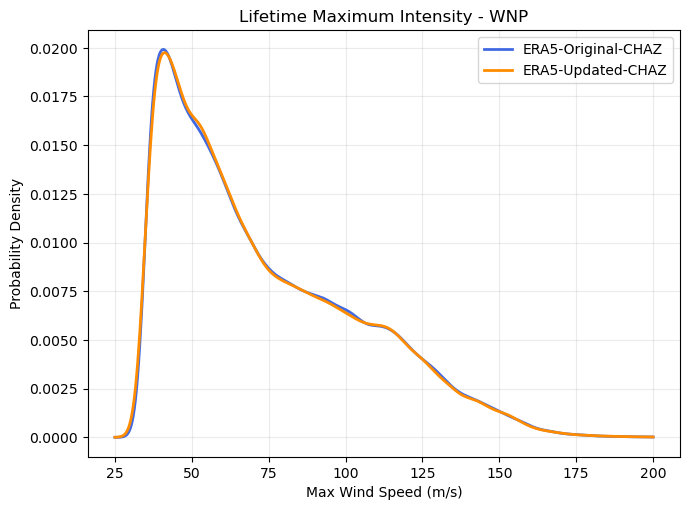

array([47.33844234, 36.24656785, 37.43470632, ..., 42.23271526,
       64.45796134, 85.6496214 ], shape=(179631,))

In [6]:
## open vmax logic might not work again, need to add effective year to output path

plot_LMI('GLOBAL')
plot_LMI('ATL')
plot_LMI('WNP')

## Alternative plot option

In [7]:
def _get_basin_mask(latitude, longitude, basin):
    """
    Determine which storms have at least one track point inside a selected ocean basin.

    latitude, longitude:
        xarray.DataArray with dimensions (lifelength, stormID)

    Returns:
        1-D boolean numpy array with length stormID
    """

    if basin == 'ATL':
        # ~100°W–20°E, 0–60°N
        point_mask = (
            (latitude >= 0) &
            (latitude <= 60) &
            (
                (longitude >= 260) |
                (longitude <= 20)
            )
        )

    elif basin == 'WNP':
        # ~100°E–180°E, 0–50°N
        point_mask = (
            (latitude >= 0) &
            (latitude <= 50) &
            (longitude >= 100) &
            (longitude <= 180)
        )

    elif basin == 'GLOBAL':
        # 0–360°, -60–60°
        point_mask = (
            (latitude >= -60) &
            (latitude <= 60)
        )

    else:
        raise ValueError(
            f"Unknown basin: {basin}. "
            "Choose from 'ATL', 'WNP', or 'GLOBAL'."
        )

    
    ## A storm counts as 'in the ocean basin' if ANY part of its track is within the basin.
    storm_mask = point_mask.any(dim='lifelength')
    return storm_mask          ## was: storm_mask.values


def get_vmax(ds, basin_key):
    vmax_all = []

    for i in ds.ens.values:
        ds_i = ds.sel(ens=i)

        ## mask dims: (year_dim, stormID)
        basin_mask = _get_basin_mask(ds_i.latitude, ds_i.longitude, basin_key)

        ## vmax dims: (year_dim, ensembleNum, stormID)
        vmax = ds_i.Mwspd.max(dim='lifelength', skipna=True)

        ## mask
        vmax = vmax.where(basin_mask)

        vmax = vmax.values.ravel()
        vmax = vmax[~np.isnan(vmax)]

        vmax_all.append(vmax)

    if not vmax_all:
        raise ValueError("No valid data found.")

    vmax_concat = np.concatenate(vmax_all)
    return vmax_concat
    

def plot_LMI_single(ds, basin_key, bin_width=5):
    fig, ax = plt.subplots(figsize=(7, 5))

    vmax = get_vmax(ds, basin_key)
    vmax = vmax[np.isfinite(vmax)]

    x_min, x_max = 25, 200
    x_grid = np.linspace(x_min, x_max, 500)
    kde = gaussian_kde(vmax)

    ## histogram (density=True to match KDE's y-scale)
    bins = np.arange(x_min, x_max + bin_width, bin_width)
    ax.hist(
        vmax,
        bins=bins,
        density=True,
        color='lightgray',
        edgecolor='white',
        zorder=1,
    )

    ## kde
    ax.plot(
        x_grid,
        kde(x_grid),
        linewidth=2,
        color='C0',
        #label=f'KDE (n={len(vmax)})',
        zorder=2,
    )

    vmax = get_vmax(ds, basin_key)

    # Remove NaNs/infinite values
    vmax = vmax[np.isfinite(vmax)]

    # Kernel density estimate
    kde = gaussian_kde(vmax)


    x_grid = np.linspace(25, 200, 500)

    pdf = kde(x_grid)

    ax.plot(
        x_grid,
        pdf,
        linewidth=2,
    )

    ax.set_xlabel('Max Wind Speed (m/s)')
    ax.set_ylabel('Probability Density')

    ax.legend()
    ax.grid(alpha=0.25)

    plt.tight_layout()

    plt.title(f'Lifetime Maximum Intensity - {basin_key}')

    plt.show()

    return vmax

In [8]:
import re

filenames = sorted(glob.glob(gv.output_path + '/ERA5_*_ens*.nc'))

def preprocess(ds):
    yr = int(ds['year'].values[0])
    fname = os.path.basename(ds.encoding['source'])
    ens = int(re.search(r'ens(\d+)', fname).group(1))
    return ds.expand_dims(year_dim=[yr], ens=[ens])

ds = xr.open_mfdataset(
    filenames,
    preprocess=preprocess,
    combine="by_coords",   # was "nested"; it uses year_dim and ens coords to place each file
).load()

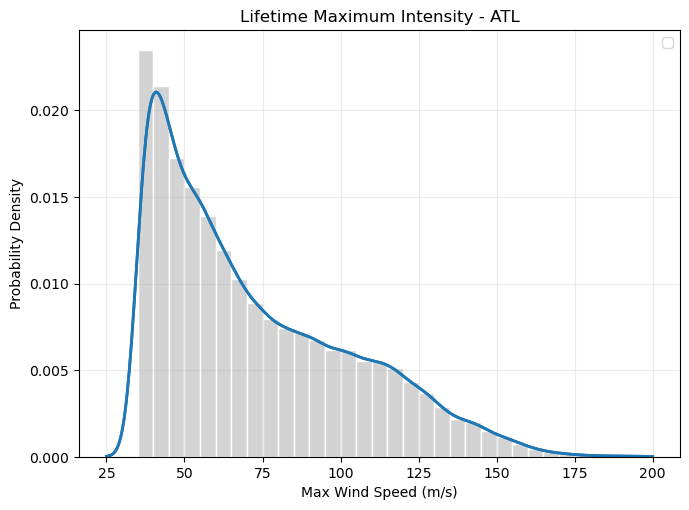

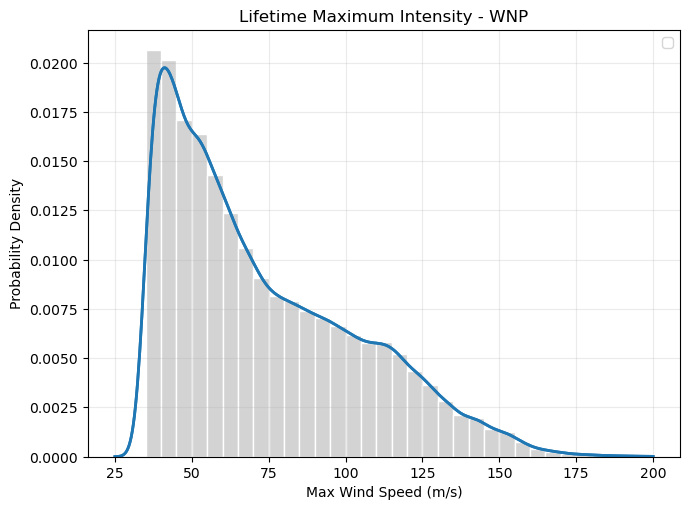

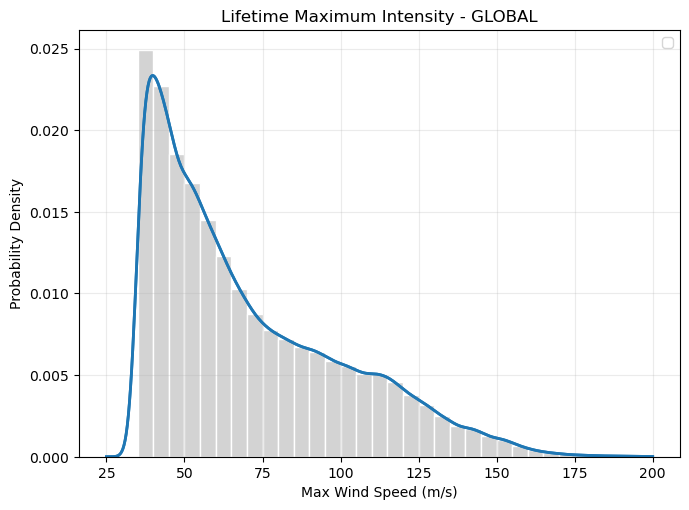

array([79.0986805 , 99.04111013, 66.91086624, ..., 85.6496214 ,
       74.15350088, 78.06731987], shape=(483130,))

In [9]:
plot_LMI_single(ds, 'ATL')
plot_LMI_single(ds, 'WNP')
plot_LMI_single(ds, 'GLOBAL')